# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis, **Crest** neural
crest) were scored in 02 against the shared **union** control pool and graph-smoothed. Here we render
them as deliverables (raw per-cell scores, house style) and evaluate **Gate 2**.

**Gate 2 (non-branching case).** Caron 2020's ALL manifold is non-branching, so the test is for a single
developmental gradient with organized cross-repression rather than a hub diverging into two arms. Three
facts, all established in 02 and cell-cycle-independent, settle it: (i) **Gast↔pSom are anti-correlated**
in space (smoothed r = −0.45; r = −0.37 after regressing out cell cycle) — organized cross-repression;
(ii) **Crest opposes both** modules (r = −0.72 vs pSom, −0.22 vs Gast; −0.65 / −0.43 residualized) as an
inverse/terminal gradient; (iii) the pattern **survives cell-cycle removal**, so it is not a proliferation
artefact. Per §1 (amended by the Wu 2021 footnote), organized Gast/pSom cross-repression with a terminal
Crest gradient **is** the non-branching pattern → **Gate 2 = GO**; with no bifurcation, **Gate 3 = NA**.
**Crest-arm FLAG:** Crest leans toward the **Gast** end (residualized r = −0.43 vs Gast, −0.65 vs pSom),
an inversion of the ideal pSom-arm enrichment — flagged, passes anyway (§2). Deliverable:
`signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print('cells:', adata.shape[0], '| scores present:', [m for m in ['Gast','pSom','Crest'] if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present | mean score = {adata.obs[lab].mean():+.4f}')

cells: 25788 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 66/81 genes present | mean score = -0.0166
pSom: 77/98 genes present | mean score = +0.0003
Crest: 93/104 genes present | mean score = -0.0104


### Gate 2 — module geography on the manifold
Quantitative test of the non-branching signature: organized Gast↔pSom cross-repression + Crest inverse
gradient, all cell-cycle-independent. Along pseudotime Gast falls (it marks the quiescent origin), pSom
is flat, and Crest rises toward the terminus.

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.3f}')
print('cell-cycle-independent (residualized, smoothed):')
for a,b in [('Gast_rcsm','pSom_rcsm'),('Crest_rcsm','Gast_rcsm'),('Crest_rcsm','pSom_rcsm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.3f}')
t = adata.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_=spearmanr(t,adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
# Crest-arm flag: which end does Crest lean to?
flag = 'Gast' if abs(np.corrcoef(adata.obs['Crest_rcsm'],adata.obs['Gast_rcsm'])[0,1]) < abs(np.corrcoef(adata.obs['Crest_rcsm'],adata.obs['pSom_rcsm'])[0,1]) else 'pSom'
print('Gate 2: organized Gast<->pSom cross-repression + Crest inverse gradient (cc-independent) -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA')
print('Crest-arm FLAG: Crest opposes pSom more strongly than Gast -> Crest sits toward the Gast end (inversion; pass anyway)')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.451
  Crest_sm vs Gast_sm: r = -0.218
  Crest_sm vs pSom_sm: r = -0.718
cell-cycle-independent (residualized, smoothed):
  Gast_rcsm vs pSom_rcsm: r = -0.372
  Crest_rcsm vs Gast_rcsm: r = -0.431
  Crest_rcsm vs pSom_rcsm: r = -0.653
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.716
  pSom_sm: rho = +0.028
  Crest_sm: rho = +0.326
Neural-crest-high decile mean pseudotime = 0.71 (terminal if ~1)
Gate 2: organized Gast<->pSom cross-repression + Crest inverse gradient (cc-independent) -> GO (non-branching)
Gate 3: no bifurcation -> NA
Crest-arm FLAG: Crest opposes pSom more strongly than Gast -> Crest sits toward the Gast end (inversion; pass anyway)


### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right (`X_umap_lin`), `size=6`, plasma, **raw** (not
smoothed) score per cell so 10x dropout is visible (binding: deliverable UMAPs show raw scores;
smoothing is for the analysis only). Colorbar ticks data-driven.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


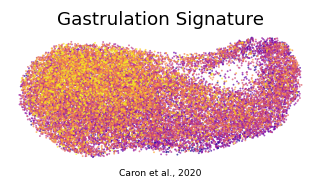

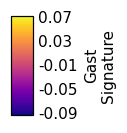

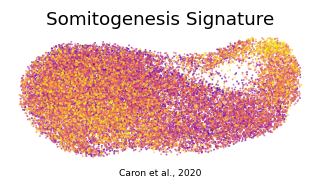

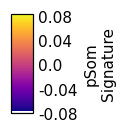

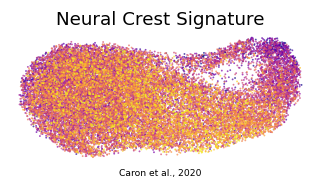

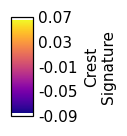

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=6, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m], vmin='p2', vmax='p98')
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Caron et al., 2020', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(np.percentile(adata.obs[m],2)), float(np.percentile(adata.obs[m],98))
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (25788, 21935)
